---
title: "02 Standard Workflow"
output: html_document
---

<!-- Generated from the companion Jupyter notebook. Open this file in RStudio and run chunks interactively. -->

# ContextNet Workflow: Ligand Activity for Contralateral Receiver Cell States

## Biological System

This tutorial uses the head-and-neck squamous cell carcinoma (HNSCC) contralateral sc-multiome dataset and restricts the analysis to **contralateral tissue** (`C`). Contralateral tissue provides one tissue context for asking which ligand activities explain receiver cell states. Paper link: [HNSCC manuscript](../README.md#citation).

In this dataset, the receiver cell states are four epithelial subtypes: **basal**, **parabasal**, **suprabasal**, and **dividing** cells. ContextNet asks which sender-cell ligands can explain the gene program that distinguishes each receiver cell state from the other cell states in the same tissue.

## Biological Question

Question addressed: **within contralateral HNSCC tissue, which sender ligands have the strongest ContextNet support for each receiver cell-state program?**

The goal is to identify ligand activities and target genes that explain receiver cell-state programs inside the contralateral tissue context. Each analysis defines one receiver cell state against the other receiver states, then asks which ligands recover that state program through the ContextNet ligand-target matrix.

## Workflow Outline

This tutorial:

- Builds a reusable `ContextNetwork` from a context-specific gene regulatory network (GRN).
- Runs a ContextNet ligand-activity analysis in one biological tissue context.
- Runs ligand prioritization for basal, parabasal, suprabasal, and dividing receiver cell states.
- Interprets ligand activity scores, ligand-target support, and ccflowR Sankey river plots. ccflowR is optional visualization support for path-level communication hypotheses: it turns sender -> ligand -> receptor -> receiver tables into river diagrams that are easier to inspect than long ranked tables.
- Exports receiver-cell result tables for downstream review.

## Environment and Data Setup

Install ContextNet before starting this tutorial using the repository [installation instructions](../README.md#installation). The cells below are not installation steps. They only load packages, set public relative data paths, and define the biological analysis used in this notebook.



In [1]:
suppressWarnings(suppressPackageStartupMessages({
    library(ContextNet)
    library(Seurat)
    library(nichenetr)
    library(dplyr)
    library(ggplot2)
    library(ccflowR)
}))

theme_set(theme_minimal(base_family = "sans"))


display_ccflowr_sankey <- function(sankey_plot, width, height, preview_file) {
    # GitHub leaves the interactive htmlwidget area blank, so the committed
    # tutorial displays only the ccflowR-generated static PNG preview.
    dir.create(dirname(preview_file), recursive = TRUE, showWarnings = FALSE)
    exported <- FALSE
    tryCatch({
        suppressMessages(ccflowR::sankey_save(sankey_plot, preview_file, width = width, height = height))
        exported <- file.exists(preview_file) && file.info(preview_file)[["size"]] > 0
    }, error = function(e) {
        stop(
            "Could not create the ccflowR PNG preview. Install Kaleido or webshot2: ",
            conditionMessage(e),
            call. = FALSE
        )
    })

    if (!exported) {
        stop("ccflowR PNG preview was not created.", call. = FALSE)
    }
    if (requireNamespace("IRdisplay", quietly = TRUE)) {
        IRdisplay::display_png(file = preview_file)
    } else {
        message("Static ccflowR figure written to ", preview_file)
    }
    invisible(sankey_plot)
}


In [2]:
# USER CONFIGURATION
# The HNSCC tutorial data should be placed under data/ after download from
# the ContextNet tutorial data release. Environment variables can override
# these defaults without changing the notebook source.

PROJECT_DIR <- normalizePath(getwd(), mustWork = TRUE)
if (basename(PROJECT_DIR) == "notebooks" &&
    file.exists(file.path(PROJECT_DIR, "..", "DESCRIPTION"))) {
    PROJECT_DIR <- normalizePath(file.path(PROJECT_DIR, ".."), mustWork = TRUE)
}
if (!file.exists(file.path(PROJECT_DIR, "DESCRIPTION"))) {
    stop("Run this notebook from the ContextNet repository root or from the notebooks/ directory.")
}
setwd(PROJECT_DIR)

display_path <- function(path) {
    normalized <- normalizePath(path, mustWork = FALSE)
    root <- normalizePath(PROJECT_DIR, mustWork = TRUE)
    if (startsWith(normalized, root)) {
        return(sub("^/", "", substring(normalized, nchar(root) + 1)))
    }
    paste0("<external>/", basename(normalized))
}

cat("Using project root:", basename(getwd()), "\n")

DATA_PATH <- file.path(PROJECT_DIR, "data")
GRN_FILE <- Sys.getenv("CONTEXTNET_TUTORIAL02_GRN", unset = file.path(DATA_PATH, "gene_x_tf.csv"))
SEURAT_FILE <- Sys.getenv("CONTEXTNET_TUTORIAL_SEURAT", unset = file.path(DATA_PATH, "seurat_obj.rds"))
NICHENET_DB <- Sys.getenv("CONTEXTNET_NICHENET_DB", unset = DATA_PATH)

# Repo-local derived outputs. The cache name is specific to the contralateral
# GRN so Tutorial 03 cannot accidentally reuse a different ligand-target matrix.
CACHE_DIR <- file.path(DATA_PATH, "cache")
NETWORK_CACHE <- file.path(CACHE_DIR, "contextnet_network_contralateral.rds")
OUTPUT_DIR <- file.path(CACHE_DIR, "tutorial-02-outputs")
RECEIVER_RESULTS_CACHE <- file.path(OUTPUT_DIR, "contralateral_receiver_results.rds")
FIGURE3_RECEIVER_RESULTS_CACHE <- file.path(OUTPUT_DIR, "contralateral_figure3_receiver_results.rds")
USE_PRECOMPUTED_RECEIVER_RESULTS <- tolower(Sys.getenv(
    "CONTEXTNET_USE_PRECOMPUTED_TUTORIAL02",
    unset = "true"
)) %in% c("true", "1", "yes")

# Analysis parameters: contralateral-only epithelial-subtype comparison.
TISSUE_COL <- "category"
TISSUE_VALUE <- "C"
GROUP_COL <- "Fine_Cell_Types"
SENDER <- NULL        # NULL auto-detects sender cell types by abundance.
RECEIVERS <- c("basal", "parabasal", "suprabasal", "dividing")
MIN_CELLS <- 500      # Minimum cells required for automatic sender inclusion.
TOP_N_LIGANDS <- 30   # Ligands retained for ranking tables, target review, and Sankey input.

# Each epithelial subtype is compared with the other epithelial subtypes.
RECEIVER_COMPARISONS <- stats::setNames(
    lapply(RECEIVERS, function(receiver) setdiff(RECEIVERS, receiver)),
    RECEIVERS
)

missing_inputs <- c(GRN_FILE, SEURAT_FILE)[!file.exists(c(GRN_FILE, SEURAT_FILE))]
if (length(missing_inputs) > 0 || !dir.exists(NICHENET_DB)) {
    stop("Missing HNSCC tutorial data. Download the tutorial files into data/ or set CONTEXTNET_TUTORIAL02_GRN, CONTEXTNET_TUTORIAL_SEURAT, and CONTEXTNET_NICHENET_DB.")
}
stopifnot(requireNamespace("ccflowR", quietly = TRUE))
cat("GRN file:", display_path(GRN_FILE), "\n")
cat("Seurat file:", display_path(SEURAT_FILE), "\n")


cat("NicheNet DB:", display_path(NICHENET_DB), "\n")


Using project root: ContextNet 


GRN file: data/gene_x_tf.csv 


Seurat file: data/seurat_obj.rds 


NicheNet DB: data 



## Step 1: Import GRN

The context-specific GRN is a gene × TF matrix (CSV) where rows are target genes, columns are transcription factors, and values are regulatory weights inferred from matched scRNA-seq + scATAC-seq data.



In [3]:
grn <- import_grn(GRN_FILE, format = "pipeline")
cat("Imported ContextGRN from:", display_path(GRN_FILE), "\n")
cat("  TFs:", length(tfs(grn)), "\n")
cat("  Target genes:", length(targets(grn)), "\n")
cat("  Regulatory edges:", length(grn), "\n")

if (length(targets(grn)) == 12742) {
    cat("HNSCC tutorial GRN dimensions match the expected contralateral analysis input.\n")
} else {
    warning("GRN dimensions differ from the HNSCC tutorial data; ligand rankings and figures may differ.")
}


→ Loading GRN from: 



ℹ Matrix dimensions: 17226 genes x 701 TFs



→ Normalizing weights per TF...



→ Converting to edge list...



✔ Imported GRN:



...

Imported ContextGRN from: data/gene_x_tf.csv 


  TFs: 701 


  Target genes: 11607 


  Regulatory edges: 2334753 


Warning message:
“GRN dimensions differ from the HNSCC tutorial data; ligand rankings and figures may differ.”


In [4]:
# Preview the regulatory evidence that will be propagated through NicheNet.
head(edges(grn))


,from,to,weight
,<chr>,<chr>,<dbl>
6,ZNF496,NOC2L,0.013845677
8,ZNF496,ISG15,0.043589601
9,ZNF496,C1orf159,0.002842452
11,ZNF496,TNFRSF18,0.018544036
12,ZNF496,SDF4,0.016673121
16,ZNF496,PUSL1,0.006506393



## Step 2: Integrate with NicheNet

This integrates the context-specific GRN with NicheNet's curated ligand-receptor interactions and signaling pathways. The result is a context-specific ligand-target matrix computed via Personalized PageRank.

Three integration modes are available:
- **`replace`** (default): Use the context-specific GRN as the regulatory layer
- **`augment`**: Add context-specific GRN edges to the prior regulatory layer
- **`weighted`**: Use a weighted combination of the prior regulatory layer and the context-specific GRN

> **Matrix reuse:** The ligand-target matrix produced here is a standard R matrix. It can be extracted with `ligand_target_matrix(network)` and used directly in a [nichenetr workflow](https://github.com/saeyslab/nichenetr/blob/master/vignettes/seurat_steps.md) wherever the workflow expects `ligand_target_matrix`. ContextNet's wrappers below use that matrix for receiver gene-set definition, ligand-activity scoring, target extraction, and ccflowR input, but the matrix itself can also be passed to native nichenetr plotting functions.

### What the `ContextNetwork` Represents

`integrate_networks()` returns a `ContextNetwork`. This is the central reusable object in ContextNet: it stores a context-specific ligand-target matrix generated by propagating NicheNet ligand-receptor/signaling information through the GRN. A column is a ligand, a row is a target gene, and each entry is the regulatory-potential score connecting that ligand to that target in this biological context.

Because this object is independent of one sender/receiver contrast, it can be saved once and reused across many downstream analyses.



In [5]:
# Use the cached ContextNetwork when available; rebuilding the ligand-target
# matrix is the slowest setup step in this tutorial.
if (file.exists(NETWORK_CACHE)) {
    network <- readRDS(NETWORK_CACHE)
    cat("Loaded cached ContextNetwork from:", display_path(NETWORK_CACHE), "\n")
} else {
    network <- integrate_networks(
        grn,
        nichenet_database = NICHENET_DB,
        mode = "replace"  # use the HNSCC GRN as the regulatory layer
    )
}
ltm <- ligand_target_matrix(network)
cat("ContextNetwork ready\n")
cat("  Ligands:", length(ligands(network)), "\n")
cat("  Target genes:", length(targets(network)), "\n")
cat("  Ligand-target matrix:", nrow(ltm), "targets x", ncol(ltm), "ligands\n")


Loaded cached ContextNetwork from: data/cache/contextnet_network_contralateral.rds 


ContextNetwork ready


  Ligands: 1226 


  Target genes: 25337 


  Ligand-target matrix: 25337 targets x 1226 ligands


In [6]:
# Cache the network for reuse so the integration step is not repeated.
if (!dir.exists(CACHE_DIR)) dir.create(CACHE_DIR, recursive = TRUE)
saveRDS(network, NETWORK_CACHE)
cat("Cached ContextNetwork to:", display_path(NETWORK_CACHE), "\n")
integration_params(network)


Cached ContextNetwork to: data/cache/contextnet_network_contralateral.rds 


$mode
[1] "replace"

$weights
NULL

$damping_factor
[1] 0.7885754

$ltf_cutoff
[1] 0.9255861

$algorithm
[1] "PPR"


## Step 3: Load Contralateral Expression Data

This workflow uses **only contralateral tissue**. Within that single tissue context, each epithelial subtype is compared against the other epithelial subtypes.



In [7]:
seurat_obj <- readRDS(SEURAT_FILE)
seurat_c <- subset(seurat_obj, subset = category == TISSUE_VALUE)
seurat_c[[TISSUE_COL]] <- droplevels(as.factor(seurat_c[[TISSUE_COL]][, 1]))
seurat_c[[GROUP_COL]] <- droplevels(as.factor(seurat_c[[GROUP_COL]][, 1]))

cat("Cells in contralateral tissue:", ncol(seurat_c), "\n")
cat("Tissue labels retained:", paste(unique(seurat_c[[TISSUE_COL]][, 1]), collapse = ", "), "\n")
cat("Receiver states:", paste(RECEIVERS, collapse = ", "), "\n")


Cells in contralateral tissue: 38826 


Tissue labels retained: C 


Receiver states: basal, parabasal, suprabasal, dividing 


In [8]:
celltype_counts <- table(seurat_c[[GROUP_COL]][, 1])
print(celltype_counts)



       B Cell   Endothelial    Fibroblast    Melanocyte        Muscle 
           25          6873          1947           166            71 
      Myeloid Myofibroblast      Neuronal        T Cell         basal 
         1600          2775            37          5488          8480 
     dividing     parabasal    suprabasal transitioning 
         2014          2193          6872           285 


In [9]:
# Auto-detect senders if not specified. The abundance-based sender set can
# include epithelial subtypes as candidate autocrine senders. Set SENDER above
# to test a narrower sender hypothesis.
if (is.null(SENDER)) {
    SENDER <- names(celltype_counts)[celltype_counts > MIN_CELLS]
}

# The manuscript Figure 3K Sankey panel uses a merged parabasal+dividing
# receiver branch only for the parabasal receiver analysis.
FIGURE3_GROUP_COL <- paste0(GROUP_COL, "_figure3")
figure3_labels <- as.character(seurat_c[[GROUP_COL]][, 1])
figure3_labels[figure3_labels %in% c("parabasal", "dividing")] <- "parabasal"
seurat_c[[FIGURE3_GROUP_COL]] <- factor(figure3_labels)
SENDER_FIGURE3 <- setdiff(SENDER, "dividing")

cat("Senders:", paste(SENDER, collapse = ", "), "\n")
cat("Receivers:", paste(RECEIVERS, collapse = ", "), "\n")
cat("Tissue context:", TISSUE_VALUE, "only\n")
cat("Figure 3K merged receiver column:", FIGURE3_GROUP_COL, "\n")


Senders: Endothelial, Fibroblast, Myeloid, Myofibroblast, T Cell, basal, dividing, parabasal, suprabasal 


Receivers: basal, parabasal, suprabasal, dividing 


Tissue context: C only


Figure 3K merged receiver column: Fine_Cell_Types_figure3 



### Analysis Design Check

This workflow asks an epithelial-subtype question inside contralateral tissue. Before scoring ligands, verify that the contralateral subset contains the four epithelial subtypes and enough candidate sender cells. Also check that the measured genes overlap the GRN and ContextNet ligand-target matrix.



In [10]:
receiver_counts <- celltype_counts[names(celltype_counts) %in% RECEIVERS]
sender_counts <- celltype_counts[names(celltype_counts) %in% SENDER]

cat("Receiver cell counts in contralateral tissue:\n")
print(receiver_counts)
cat("\nSender cell types retained with >", MIN_CELLS, " cells:\n", sep = "")
print(sender_counts)

expr_genes <- rownames(seurat_c)
cat("\nGRN targets measured:", length(intersect(targets(grn), expr_genes)), "/", length(targets(grn)), "\n")
cat("Network targets measured:", length(intersect(targets(network), expr_genes)), "/", length(targets(network)), "\n")
cat("Network ligands measured:", length(intersect(ligands(network), expr_genes)), "/", length(ligands(network)), "\n")


Receiver cell counts in contralateral tissue:



     basal   dividing  parabasal suprabasal 
      8480       2014       2193       6872 



Sender cell types retained with >500 cells:



  Endothelial    Fibroblast       Myeloid Myofibroblast        T Cell 
         6873          1947          1600          2775          5488 
        basal      dividing     parabasal    suprabasal 
         8480          2014          2193          6872 



GRN targets measured: 10839 / 11607 


Network targets measured: 13975 / 25337 


Network ligands measured: 698 / 1226 



## Step 4: Predict Ligand Activity for Each Receiver State

For each epithelial subtype, ContextNet defines the receiver gene program as that subtype versus the other epithelial subtypes **within contralateral tissue**. The ligand ranking then asks which sender-cell ligands best recover that receiver program through the context-specific ligand-target matrix.



In [11]:
run_receiver_analysis <- function(receiver,
                                  comparison = RECEIVER_COMPARISONS[[receiver]],
                                  sender_use = SENDER,
                                  group_col = GROUP_COL) {
    cat("\nReceiver:", receiver, "vs", paste(comparison, collapse = ", "), "\n")
    suppressWarnings(predict_ligand_activity_nichenet(
        object = seurat_c,
        network = network,
        sender = sender_use,
        receiver = receiver,
        group_col = group_col,
        ident_col = group_col,
        ident_1 = receiver,
        ident_2 = comparison,
        de_subset_receiver = FALSE,
        logfc_threshold = 0.25,
        min_pct = 0.2,
        min_pct_de = 0.05,
        nichenet_database = NICHENET_DB,
        top_n_ligands = TOP_N_LIGANDS  # retain top ligands for tables, targets, and flow plots
    ))
}

if (USE_PRECOMPUTED_RECEIVER_RESULTS && file.exists(RECEIVER_RESULTS_CACHE)) {
    receiver_results <- readRDS(RECEIVER_RESULTS_CACHE)
    receiver_results <- receiver_results[RECEIVERS]
    cat("Loaded cached receiver analyses from:", display_path(RECEIVER_RESULTS_CACHE), "\n")
} else {
    receiver_results <- stats::setNames(lapply(RECEIVERS, run_receiver_analysis), RECEIVERS)
}
result <- receiver_results[["basal"]]
cat("\nCompleted receiver analyses:", paste(names(receiver_results), collapse = ", "), "\n")

if (USE_PRECOMPUTED_RECEIVER_RESULTS && file.exists(FIGURE3_RECEIVER_RESULTS_CACHE)) {
    figure3_receiver_results <- readRDS(FIGURE3_RECEIVER_RESULTS_CACHE)
    figure3_receiver_results <- figure3_receiver_results[RECEIVERS]
    cat("Loaded Figure 3K receiver analyses from:", display_path(FIGURE3_RECEIVER_RESULTS_CACHE), "\n")
} else {
    figure3_receiver_results <- receiver_results
    figure3_receiver_results[["parabasal"]] <- run_receiver_analysis(
        receiver = "parabasal",
        comparison = c("suprabasal", "basal"),
        sender_use = SENDER_FIGURE3,
        group_col = FIGURE3_GROUP_COL
    )
}


Loaded cached receiver analyses from: data/cache/tutorial-02-outputs/contralateral_receiver_results.rds 



Completed receiver analyses: basal, parabasal, suprabasal, dividing 


Loaded Figure 3K receiver analyses from: data/cache/tutorial-02-outputs/contralateral_figure3_receiver_results.rds 



### Receiver Program

Each receiver result stores the genes that define that epithelial state in contralateral tissue. These gene sets are the target programs that ligand activity tries to recover.



In [12]:
receiver_program_summary <- bind_rows(lapply(names(receiver_results), function(receiver) {
    params <- parameters(receiver_results[[receiver]])
    data.frame(
        receiver = receiver,
        comparison = paste(RECEIVER_COMPARISONS[[receiver]], collapse = ", ") ,
        geneset_size = length(params$geneset_oi),
        first_genes = paste(utils::head(params$geneset_oi, 8), collapse = ", "),
        stringsAsFactors = FALSE
    )
}))
receiver_program_summary


receiver,comparison,geneset_size,first_genes
<chr>,<chr>,<int>,<chr>
basal,"parabasal, suprabasal, dividing",2819,"COL17A1, IL1R2, KCNQ5, CDH13, SOX5, PCDH7, CXCL14, LAMB4"
parabasal,"basal, suprabasal, dividing",1355,"KRT5, DENND2C, NCOA7, LY6D, ABI1, LINC02006, DSG3, ELF1"
suprabasal,"basal, parabasal, dividing",2533,"SCEL, A2ML1, SULT2B1, CYP2C18, RHCG, CD24, MBOAT2, IVL"
dividing,"basal, parabasal, suprabasal",2530,"MKI67, ASPM, CENPF, DIAPH3, TOP2A, ANLN, CENPE, TPX2"



## Step 5: Explore Results

`receiver_results` is a named list of `ContextResult` objects. Each object stores one epithelial-subtype analysis in contralateral tissue. Keep subtype-specific results separate during interpretation: a high ligand score for basal cells is not automatically evidence for the same ligand in parabasal, suprabasal, or dividing cells.



In [13]:
top_ligands_by_receiver <- lapply(receiver_results, top_ligands)
top_ligands_by_receiver


$basal
 [1] "CDH6""BACE2""FGF13""EZR""COL18A1""SEMA3A"  
 [7] "ANGPTL4""MIF""SFRP1""JAM2""SEMA5A""S100B"   
[13] "SERPINF1""WNT4""LAMA4""ADAM15""GPC6""COL4A2"  
[19] "GPI""RTN4""LGALS3BP""COL6A2""DLL1""TNC"     
[25] "WNT9A""ZNRF3""CXCL12""DSC3""COL12A1""CNTN1"   

$parabasal
 [1] "GLG1""POSTN""LRIG2""SPON2""DLK2""PTPRK""OCLN""MMP2"  
 [9] "LAMC1""TIMP2""THBS4""FBLN1""JAM2""IL16""JAML""COL5A1"
[17] "PLAT""WNT2B""FST""ENG""CD7""BMP7""ITGB2""PRSS3" 
[25] "BMP4""PTN""CNTN4""SELE""GJB2""JAM3"  

$suprabasal
 [1] "ALCAM""ANGPTL1""CEACAM1""FBN1""F13A1""GJB6""TIMP1"  
 [8] "NUCB2""PLAT""CD226""ICAM1""IGSF3""TGFBI""EFNA1"  
[15] "LRPAP1""FGF7""PSAP""ANGPT1""NECTIN1""ANGPT2""DSG1"   
[22] "ADAM17""EFNA5""IL1B""CD6""ADAM9""CDH3""NAMPT"  
[29] "MMP9""SEMA3C" 

$dividing
 [1] "DLK2""CKLF""LRIG2""POSTN""TIMP3""SEMA4B""PTPRK""COL1A2"
 [9] "LAMC1""TNXB""FST""BACE2""COL6A1""GJB2""LRP1B""FBLN1" 
[17] "PTN""SEMA3A""LAMA5""WNT9A""WNT2B""IL16""COL3A1""LAMB1" 
[25] "DLL1""TSPAN5""CADM1""MXRA5""S100A4""ADAM15"

In [14]:
activities_tbl <- bind_rows(lapply(names(receiver_results), function(receiver) {
    tbl <- ligand_activities(receiver_results[[receiver]])
    tbl$receiver <- receiver
    tbl
}))

observed_top_ligands <- activities_tbl %>%
    group_by(receiver) %>%
    arrange(desc(aupr_corrected), .by_group = TRUE) %>%
    slice_head(n = 1) %>%
    ungroup() %>%
    select(receiver, test_ligand)

if (length(targets(grn)) == 12742) {
    expected_top_ligands <- c(
        basal = "CDH6",
        parabasal = "GLG1",
        suprabasal = "ALCAM",
        dividing = "DLK2"
    )
    observed_named <- stats::setNames(observed_top_ligands$test_ligand, observed_top_ligands$receiver)
    if (!all(observed_named[names(expected_top_ligands)] == expected_top_ligands)) {
        stop("HNSCC tutorial alignment check failed: top ligands do not match the expected contralateral analysis output.")
    }
    cat("HNSCC tutorial alignment check passed: top ligand per epithelial subtype matches the expected output.\n")
}

activities_tbl %>%
    group_by(receiver) %>%
    slice_max(order_by = aupr_corrected, n = 6, with_ties = FALSE) %>%
    ungroup() %>%
    select(receiver, test_ligand, aupr_corrected, aupr, auroc, pearson)


receiver,test_ligand,aupr_corrected,aupr,auroc,pearson
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
basal,CDH6,0.2498574523,0.6707525,0.7017909,0.3617662608
basal,BACE2,0.2310864022,0.6519814,0.6948849,0.3274071154
basal,FGF13,0.2306733502,0.6515684,0.6886514,0.3279205899
basal,EZR,0.2262615732,0.6471566,0.6869737,0.3333450416
basal,COL18A1,0.2240989230,0.6449939,0.6812442,0.3330298391
basal,SEMA3A,0.2220752239,0.6429702,0.6868685,0.3276082729
dividing,DLK2,0.0224997975,0.3325549,0.5003436,0.0509070096
dividing,CKLF,0.0126304328,0.3226856,0.4894421,0.0364469736
dividing,LRIG2,0.0001525653,0.3102077,0.4895271,0.0058086508


In [15]:
targets_tbl <- bind_rows(lapply(names(receiver_results), function(receiver) {
    data.frame(receiver = receiver, target = top_targets(receiver_results[[receiver]], n = 20))
}))
head(targets_tbl, 20)


,receiver,target
,<chr>,<chr>
1,basal,SEMA4A
2,basal,ZBTB16
3,basal,ITGA3
4,basal,MEGF6
5,basal,FTH1
6,basal,COL18A1
7,basal,C5orf56
8,basal,NGFR
9,basal,LGR6


In [16]:
links_tbl <- bind_rows(lapply(names(receiver_results), function(receiver) {
    tbl <- ligand_target_links(receiver_results[[receiver]])
    tbl$receiver <- receiver
    tbl
}))
head(links_tbl)


ligand,target,weight,receiver
<chr>,<chr>,<dbl>,<chr>
CDH6,AASDH,2.231364e-05,basal
CDH6,AASS,4.875406e-04,basal
CDH6,ABCA1,2.977984e-04,basal
CDH6,ABCB9,9.757312e-04,basal
CDH6,ABCC10,2.712620e-03,basal
CDH6,ABCC3,1.841513e-03,basal


In [17]:
analysis_params <- lapply(receiver_results, parameters)
names(analysis_params)
analysis_params$basal[c("sender", "receiver", "ident_1", "ident_2", "de_subset_receiver")]


[1] "basal""parabasal""suprabasal""dividing"

$sender
[1] "Endothelial""Fibroblast""Myeloid""Myofibroblast"
[5] "T Cell""basal""dividing""parabasal"    
[9] "suprabasal"   

$receiver
[1] "basal"

$ident_1
[1] "basal"

$ident_2
[1] "parabasal""suprabasal""dividing"  

$de_subset_receiver
[1] FALSE

In [18]:
# Extract ordinary R objects for downstream analysis.
ltm <- ligand_target_matrix(network)
cat("Activity rows across receivers:", nrow(activities_tbl), "\n")
cat("Ligand-target support rows across receivers:", nrow(links_tbl), "\n")
cat("Ligand-target matrix dimensions:", nrow(ltm), "x", ncol(ltm), "\n")


Activity rows across receivers: 930 


Ligand-target support rows across receivers: 236160 


Ligand-target matrix dimensions: 25337 x 1226 



These extracted tables are the recommended interface for interpretation and reporting. Use `activities_tbl` for receiver-specific ligand rankings, `links_tbl` to explain target-gene support, and `receiver_program_summary` to report which receiver gene program was tested.

## Step 6: Visualize

### Ligand Activity Bar Plot



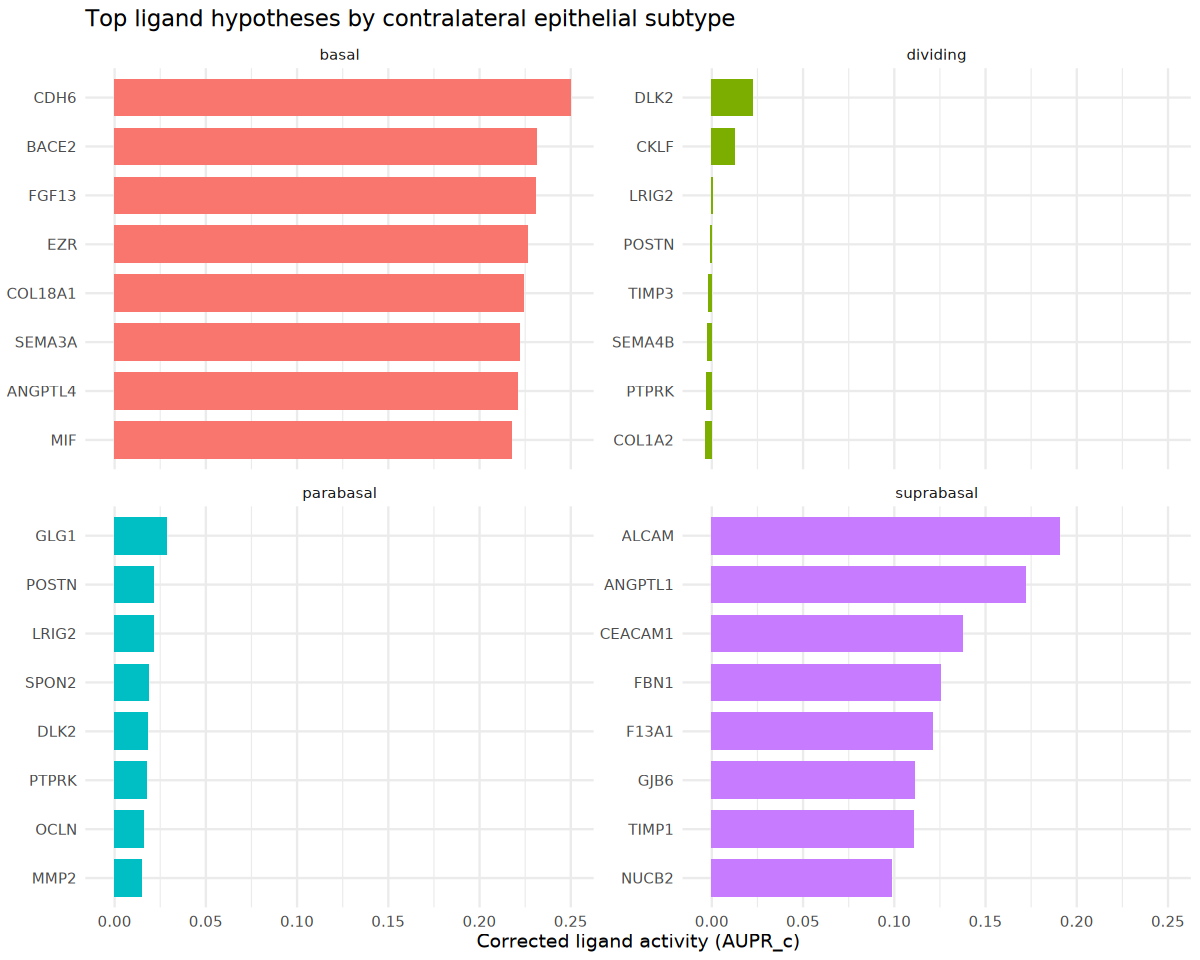

In [19]:
options(repr.plot.width = 10, repr.plot.height = 8)

top_act <- activities_tbl %>%
    group_by(receiver) %>%
    slice_max(order_by = aupr_corrected, n = 8, with_ties = FALSE) %>%
    ungroup() %>%
    mutate(label = paste(receiver, test_ligand, sep = "__"))

ggplot(top_act, aes(x = aupr_corrected, y = reorder(label, aupr_corrected), fill = receiver)) +
    geom_col(width = 0.75) +
    facet_wrap(~ receiver, scales = "free_y", ncol = 2) +
    labs(
        x = "Corrected ligand activity (AUPR_c)",
        y = NULL,
        title = "Top ligand hypotheses by contralateral epithelial subtype"
    ) +
    scale_y_discrete(labels = function(x) sub(".*__", "", x)) +
    guides(fill = "none")



**Interpretation**: The corrected AUPR (`AUPR_c`) is calculated separately for each epithelial-subtype program. Compare ligands within a subtype panel, not across panels as if they were one global test. A high score means the ligand-target model recovers the genes distinguishing that epithelial subtype from the other epithelial subtypes in contralateral tissue.

### Ligand Activity Heatmap (nichenetr)



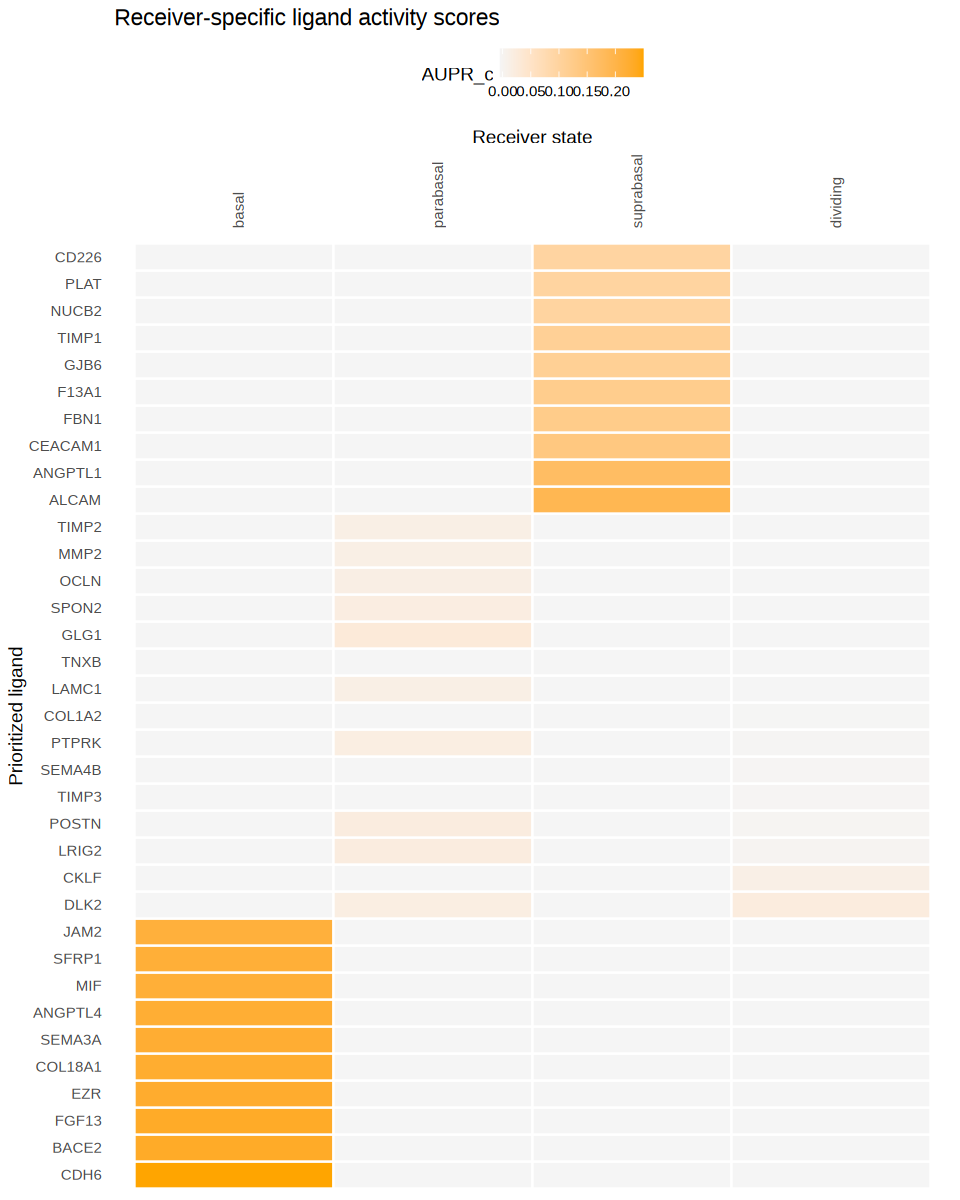

In [20]:
options(repr.plot.width = 8, repr.plot.height = 10)

activity_wide <- activities_tbl %>%
    group_by(receiver) %>%
    slice_max(order_by = aupr_corrected, n = 10, with_ties = FALSE) %>%
    ungroup() %>%
    select(receiver, test_ligand, aupr_corrected)

ligand_rows <- unique(activity_wide$test_ligand)
activity_matrix <- matrix(NA_real_, nrow = length(ligand_rows), ncol = length(RECEIVERS),
                          dimnames = list(ligand_rows, RECEIVERS))
for (i in seq_len(nrow(activity_wide))) {
    activity_matrix[activity_wide$test_ligand[i], activity_wide$receiver[i]] <- activity_wide$aupr_corrected[i]
}
activity_matrix[is.na(activity_matrix)] <- min(activity_wide$aupr_corrected, na.rm = TRUE)

suppressWarnings(print(
    nichenetr::make_heatmap_ggplot(
        activity_matrix,
        y_name = "Prioritized ligand",
        x_name = "Receiver state",
        legend_title = "AUPR_c",
        color = "orange"
    ) + ggtitle("Receiver-specific ligand activity scores")
))



### Ligand-Target Heatmap for One Receiver

The full four-epithelial-subtype Sankey plot below is the best overview. A ligand-target heatmap is more readable when focused on one epithelial subtype, so the basal program is shown as an example of how to inspect target-gene support.



Basal heatmap matrix: 33 targets x 30 ligands


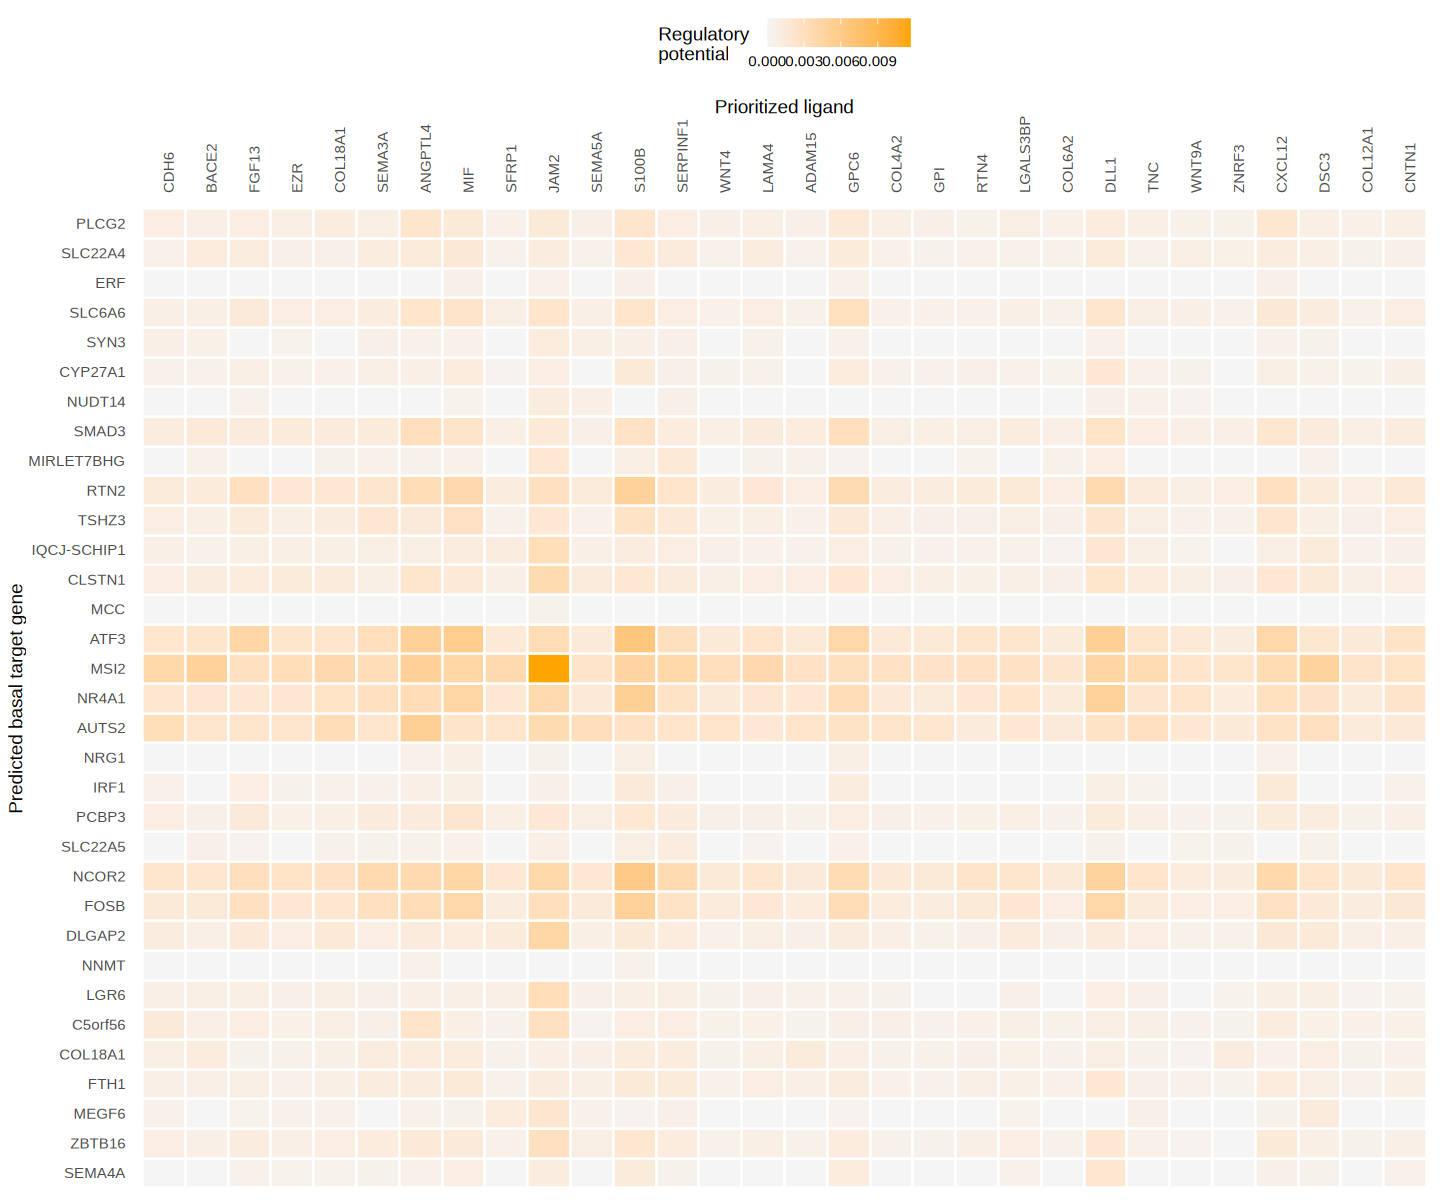

In [21]:
options(repr.plot.width = 12, repr.plot.height = 10)

receiver_to_show <- "basal"
best_ligands <- top_ligands(receiver_results[[receiver_to_show]])
best_targets <- top_targets(receiver_results[[receiver_to_show]], n = 50)
ltm <- ligand_target_matrix(network)

target_rows <- intersect(best_targets, rownames(ltm))
ligand_cols <- intersect(best_ligands, colnames(ltm))
vis_matrix <- as.matrix(ltm[target_rows, ligand_cols, drop = FALSE])

nonzero <- vis_matrix[vis_matrix > 0]
if (length(nonzero) > 0) {
    vis_matrix[vis_matrix < stats::quantile(nonzero, 0.33)] <- 0
}
vis_matrix <- vis_matrix[rowSums(vis_matrix) > 0, , drop = FALSE]

cat("Basal heatmap matrix:", nrow(vis_matrix), "targets x", ncol(vis_matrix), "ligands\n")
if (nrow(vis_matrix) == 0 || ncol(vis_matrix) == 0) {
    stop("No ligand-target links remain for plotting. Try lowering the filtering threshold or increasing TOP_N_LIGANDS.")
}

suppressWarnings(print(nichenetr::make_heatmap_ggplot(
    vis_matrix,
    y_name = "Predicted basal target gene",
    x_name = "Prioritized ligand",
    legend_title = "Regulatory\npotential",
    color = "orange",
    x_axis_position = "top"
)))



**Interpretation**: This heatmap shows the regulatory-potential score between top ligands (columns) and their predicted target genes (rows) from the context-specific ligand-target matrix. Entries below the 33rd percentile are set to zero for visual clarity. Ligands with many non-zero entries support a broad set of targets; sparse columns indicate more specific regulatory effects.

### Sankey River Plot with ccflowR

The bar plot ranks ligands and the heatmap shows target-gene support. The ccflowR Sankey river plot asks the path-level question: **which sender -> ligand -> receptor -> epithelial-subtype routes explain the strongest contralateral subtype hypotheses?**

This cell builds the `subset_data_top3` object used for the HNSCC Figure 3K tutorial panel. It prepares each epithelial subtype separately, uses the merged parabasal+dividing branch for the parabasal receiver, keeps the top three sender cell types per ligand-receptor pair by ligand expression, normalizes corrected AUPR over all ligands tested for that receiver, combines subtypes in the reference order (`basal`, `parabasal`, `dividing`, `suprabasal`), then applies the shared `threshold_quantile = 0.91` cutoff. The final Figure 3K plotting table follows the manuscript script's sparse ligand-order table and restores only the manuscript-required basal -> DLK2 -> NOTCH1 -> parabasal path from the unthresholded top-three-sender table when the current public package scores it just below the cutoff.

The final plot uses a strict global top-path threshold. If one epithelial subtype is absent from the printed `subset_data_top3` receiver list, its paths did not survive this shared threshold; the subtype analysis was still performed. Use the subtype-specific ligand tables above for all four epithelial subtypes, and lower `threshold_quantile` for a denser Sankey view.



In [22]:
# Build the subset_data_top3 object used by the HNSCC Figure 3K tutorial panel.
# Keep the same ligand count used for ranking so the table and river plot summarize the same hypotheses.
data_basal <- prepare_for_ccflowr(
    figure3_receiver_results[["basal"]], expression_data = seurat_c, network = network,
    top_n_ligands = TOP_N_LIGANDS, group_col = GROUP_COL, min_cells = MIN_CELLS,
    aupr_normalization = "all_corrected_aupr"
)

data_parabasal <- prepare_for_ccflowr(
    figure3_receiver_results[["parabasal"]], expression_data = seurat_c, network = network,
    top_n_ligands = TOP_N_LIGANDS, group_col = FIGURE3_GROUP_COL, min_cells = MIN_CELLS,
    aupr_normalization = "all_corrected_aupr"
)

data_dividing <- prepare_for_ccflowr(
    figure3_receiver_results[["dividing"]], expression_data = seurat_c, network = network,
    top_n_ligands = TOP_N_LIGANDS, group_col = GROUP_COL, min_cells = MIN_CELLS,
    aupr_normalization = "all_corrected_aupr"
)

data_suprabasal <- prepare_for_ccflowr(
    figure3_receiver_results[["suprabasal"]], expression_data = seurat_c, network = network,
    top_n_ligands = TOP_N_LIGANDS, group_col = GROUP_COL, min_cells = MIN_CELLS,
    aupr_normalization = "all_corrected_aupr"
)

all_ligand_aupr_normalization <- function(df, result) {
    activities <- ligand_activities(result)
    ligand_col <- if ("test_ligand" %in% colnames(activities)) "test_ligand" else "ligand"
    values <- activities$aupr_corrected
    denom <- max(values, na.rm = TRUE) - min(values, na.rm = TRUE)
    if (!is.finite(denom) || denom == 0) {
        stop("Cannot normalize AUPR: zero or invalid range.")
    }
    normalized <- (values - min(values, na.rm = TRUE)) / denom
    norm_map <- stats::setNames(normalized, activities[[ligand_col]])
    missing_ligands <- setdiff(unique(df$ligand), names(norm_map))
    if (length(missing_ligands) > 0) {
        stop("Missing AUPR normalization for ligands: ", paste(missing_ligands, collapse = ", "))
    }
    df$weighted_score <- (df$ligand_expression + unname(norm_map[df$ligand])) / 2
    df
}

data_basal <- all_ligand_aupr_normalization(data_basal, figure3_receiver_results[["basal"]])
data_parabasal <- all_ligand_aupr_normalization(data_parabasal, figure3_receiver_results[["parabasal"]])
data_dividing <- all_ligand_aupr_normalization(data_dividing, figure3_receiver_results[["dividing"]])
data_suprabasal <- all_ligand_aupr_normalization(data_suprabasal, figure3_receiver_results[["suprabasal"]])

limit_top3_senders_by_ligand_expr <- function(df) {
    initial_n <- nrow(df)
    filtered_df <- df %>%
        group_by(ligand, receptor) %>%
        slice_max(order_by = ligand_expression, n = 3, with_ties = FALSE) %>%
        ungroup()
    cat(sprintf("Interactions removed: %d\n", initial_n - nrow(filtered_df)))
    filtered_df
}

data_basal_top3 <- limit_top3_senders_by_ligand_expr(data_basal)
data_parabasal_top3 <- limit_top3_senders_by_ligand_expr(data_parabasal)
data_dividing_top3 <- limit_top3_senders_by_ligand_expr(data_dividing)
data_suprabasal_top3 <- limit_top3_senders_by_ligand_expr(data_suprabasal)

combined_data_top3 <- combine_sankey_data(
    data_basal_top3,
    data_parabasal_top3,
    data_dividing_top3,
    data_suprabasal_top3,
    threshold_quantile = 0
)
subset_data_top3 <- combine_sankey_data(
    data_basal_top3,
    data_parabasal_top3,
    data_dividing_top3,
    data_suprabasal_top3,
    threshold_quantile = 0.91
)

ligand_order_requested <- c(
    "CDH6", "GPC6", "COL4A2", "ANGPTL4", "COL18A", "COL12A1", "COL6A2",
    "ANGPTL1", "LAMA4", "SERPINF1", "SEMA3A", "S100B", "ALCAM", "DLK2"
)
receptor_order_requested <- c(
    "PTGFRN", "LRP1", "ITGB5", "DDR1", "ITGB1", "SDC1", "SDC4", "GPC1",
    "ITGA2", "PTPRS", "ITGAV", "LRP6", "PLXDC2", "ITGA6", "ITGA3", "PLXNA2",
    "NRP2", "NRP1", "ALCAM", "NOTCH1"
)
ligand_order <- ligand_order_requested
ligands_present <- unique(subset_data_top3$ligand)
receptors_present <- unique(subset_data_top3$receptor)
if ("COL18A" %in% ligand_order && !"COL18A" %in% ligands_present && "COL18A1" %in% ligands_present) {
    ligand_order[ligand_order == "COL18A"] <- "COL18A1"
    message("Using COL18A1 in place of requested COL18A because COL18A1 is present in subset_data_top3 and COL18A is not.")
}
missing_ligands <- setdiff(ligand_order, ligands_present)
missing_receptors <- setdiff(receptor_order_requested, receptors_present)
if (length(missing_ligands) > 0) {
    warning("Requested Figure 3K ligands absent from subset_data_top3: ", paste(missing_ligands, collapse = ", "))
}
if (length(missing_receptors) > 0) {
    warning("Requested Figure 3K receptors absent from subset_data_top3: ", paste(missing_receptors, collapse = ", "))
}
figure3_required_paths <- combined_data_top3 %>%
    filter(sender == "basal", ligand == "DLK2", receptor == "NOTCH1", receiver == "parabasal")
if (length(targets(grn)) == 12742 && nrow(figure3_required_paths) == 0) {
    stop("Expected basal -> DLK2 -> NOTCH1 -> parabasal path is missing before thresholding.")
}
required_path_in_subset <- subset_data_top3 %>%
    filter(sender == "basal", ligand == "DLK2", receptor == "NOTCH1", receiver == "parabasal") %>%
    nrow() > 0

figure3_data <- bind_rows(subset_data_top3, figure3_required_paths) %>%
    distinct() %>%
    filter(ligand %in% ligand_order)

if (length(targets(grn)) == 12742 &&
    nrow(figure3_data %>% filter(sender == "basal", ligand == "DLK2", receptor == "NOTCH1", receiver == "parabasal")) == 0) {
    stop("Expected Figure 3K plotted table to include basal -> DLK2 -> NOTCH1 -> parabasal.")
}

# Backward-compatible alias for downstream export code; this is the exact plotted Figure 3K table.
sankey_data <- figure3_data

cat("Raw ccflowR path rows:",
    nrow(data_basal) + nrow(data_parabasal) + nrow(data_dividing) + nrow(data_suprabasal), "\n")
cat("Rows in combined_data_top3 before threshold:", nrow(combined_data_top3), "\n")
cat("Rows in subset_data_top3:", nrow(subset_data_top3), "\n")
cat("Receivers in subset_data_top3:", paste(sort(unique(subset_data_top3$receiver)), collapse = ", "), "\n")
cat("Required Figure 3K manuscript path in thresholded table:", required_path_in_subset, "\n")
cat("Required Figure 3K manuscript paths restored:", nrow(figure3_required_paths), "\n")
cat("Rows in Figure 3K plotted table:", nrow(figure3_data), "\n")
cat("Receivers in Figure 3K plotted table:", paste(sort(unique(figure3_data$receiver)), collapse = ", "), "\n")
head(figure3_data)


ℹ Excluding 5 cell types with <500 cells: "B Cell (25)", "Melanocyte (166)", "Muscle (71)", "Neuronal (37)", and "transitioning (285)"



ℹ Kept 9 sender cell types (270/420 rows)



✔ Prepared 657 links for ccflowR visualization



ℹ Excluding 5 cell types with <500 cells: "B Cell (25)", "Melanocyte (166)", "Muscle (71)", "Neuronal (37)", and "transitioning (285)"



ℹ Kept 8 sender cell types (240/390 rows)



...

Required Figure 3K manuscript path in thresholded table: FALSE 


Required Figure 3K manuscript paths restored: 1 


Rows in Figure 3K plotted table: 48 


Receivers in Figure 3K plotted table: basal, dividing, parabasal, suprabasal 


sender,ligand,receptor,receiver,weighted_score,ligand_expression,weight,scaled_weighted_score,scaled_activity,scaled_ligand_expression,scaled_receptor_expression
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Myofibroblast,ANGPTL4,ITGAV,basal,0.8612747,0.8348512,0.1086988,0.7859990,0.7859990,0.7236064,0.005159026
Myofibroblast,ANGPTL4,ITGB1,basal,0.8612747,0.8348512,0.4858738,0.7859990,0.7859990,0.7236064,0.262353316
Myofibroblast,ANGPTL4,SDC1,basal,0.8612747,0.8348512,0.4907337,0.7859990,0.7859990,0.7236064,0.265667275
Myofibroblast,ANGPTL4,SDC4,basal,0.8612747,0.8348512,0.4671493,0.7859990,0.7859990,0.7236064,0.249585098
Myofibroblast,CDH6,PTGFRN,basal,0.9877696,0.9755391,0.3796261,1.0000000,1.0000000,0.9599965,0.189903363
Fibroblast,COL12A1,ITGA2,basal,0.8847728,0.9481395,0.2841939,0.8257525,0.8257525,0.9139584,0.124828500


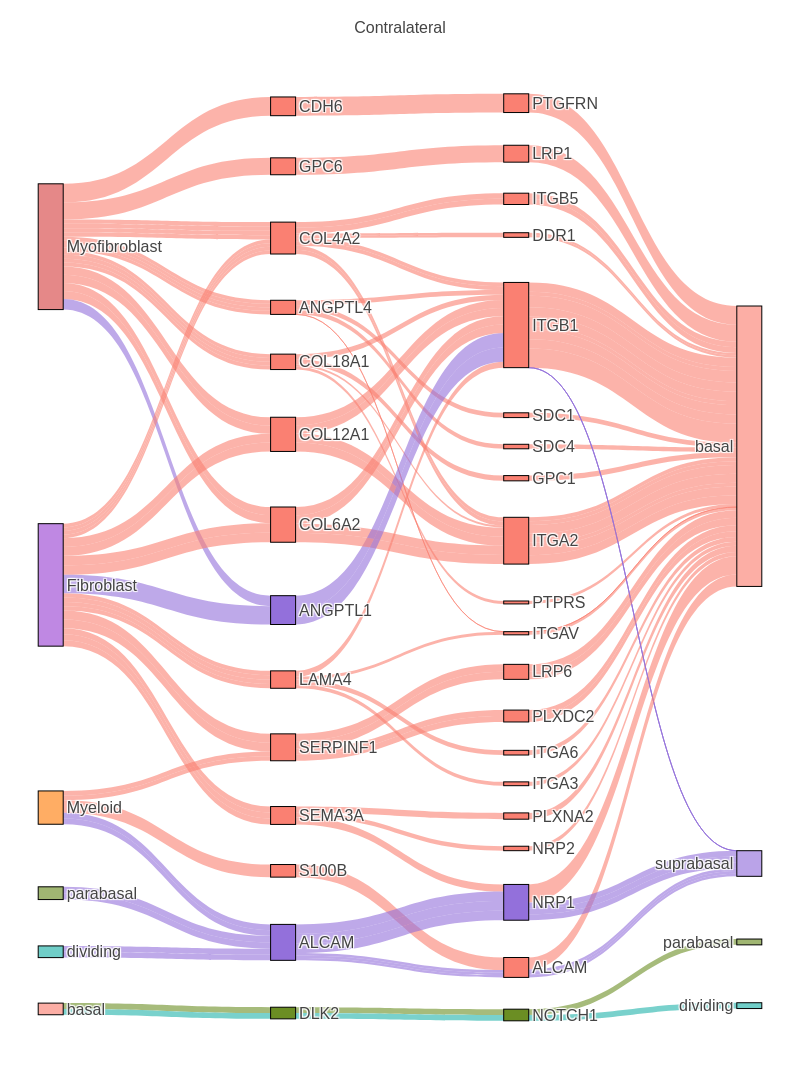

In [23]:
celltype_colors <- c(
    "B Cell" = "#17BECFA3", "Endothelial" = "#E89FBDA3",
    "Epithelial" = "#1F77B4A3", "Fibroblast" = "#9C46D3A3", "Melanocyte" = "#8C564BA3",
    "Muscle" = "#FCDD00A3", "Myeloid" = "#FF7F0EA3",
    "Myofibroblast" = "#D64545A3", "Neuronal" = "#7F7F7FA3",
    "T Cell" = "#006837A3", "basal" = "#FA8072A3",
    "dividing" = "#20B2AAA3", "other" = "#C5B0D5A3", "parabasal" = "#6B8E23A3",
    "suprabasal" = "#9370DBA3", "transitioning" = "#FFA500A3"
)
PLOT_FONT_SIZE <- 16

sankey_plot <- suppressMessages(
    ccflowR::sankey_plot(figure3_data, colors = celltype_colors) +
        ccflowR::sankey_order(ligands = ligand_order, receptors = receptor_order_requested) +
        ccflowR::sankey_colors(by = "receiver") +
        ccflowR::sankey_alpha(0.6) +
        ccflowR::sankey_title("Contralateral") +
        ccflowR::sankey_font(family = "Arial", size = PLOT_FONT_SIZE) +
        ccflowR::sankey_labels(size = PLOT_FONT_SIZE) +
        ccflowR::sankey_layout(width = 800, height = 1083)
)
display_ccflowr_sankey(
    sankey_plot,
    width = 800,
    height = 1083,
    preview_file = file.path(PROJECT_DIR, "notebooks", "figures", "02-ccflowr-sankey.png")
)



Static GitHub preview:

![Figure 3K ccflowR Sankey river plot](figures/02-ccflowr-sankey.png)

## Step 7: Export

### Save and Load Results



In [24]:
if (!dir.exists(OUTPUT_DIR)) dir.create(OUTPUT_DIR, recursive = TRUE)

saveRDS(receiver_results, file.path(OUTPUT_DIR, "contralateral_receiver_results.rds"))
saveRDS(figure3_receiver_results, FIGURE3_RECEIVER_RESULTS_CACHE)
write.csv(activities_tbl, file.path(OUTPUT_DIR, "receiver_ligand_activities.csv"), row.names = FALSE)
write.csv(links_tbl, file.path(OUTPUT_DIR, "receiver_ligand_target_links.csv"), row.names = FALSE)
write.csv(sankey_data, file.path(OUTPUT_DIR, "contralateral_sankey_data.csv"), row.names = FALSE)
write.csv(subset_data_top3, file.path(OUTPUT_DIR, "contralateral_subset_data_top3.csv"), row.names = FALSE)
write.csv(figure3_data, file.path(OUTPUT_DIR, "contralateral_figure3_sankey_data.csv"), row.names = FALSE)

cat("Saved receiver result list and export tables to:", OUTPUT_DIR, "\n")


Saved receiver result list and export tables to:  


In [25]:
receiver_results_loaded <- readRDS(file.path(OUTPUT_DIR, "contralateral_receiver_results.rds"))
names(receiver_results_loaded)


[1] "basal""parabasal""suprabasal""dividing"


### Export Tables



In [26]:
# A compact report table for manuscripts or lab review.
report_tbl <- activities_tbl %>%
    group_by(receiver) %>%
    slice_max(order_by = aupr_corrected, n = 10, with_ties = FALSE) %>%
    ungroup() %>%
    select(receiver, ligand = test_ligand, aupr_corrected, aupr, auroc, pearson)

write.csv(report_tbl, file.path(OUTPUT_DIR, "top_ligands_by_receiver.csv"), row.names = FALSE)
report_tbl


receiver,ligand,aupr_corrected,aupr,auroc,pearson
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
basal,CDH6,0.2498574523,0.6707525,0.7017909,0.3617662608
basal,BACE2,0.2310864022,0.6519814,0.6948849,0.3274071154
basal,FGF13,0.2306733502,0.6515684,0.6886514,0.3279205899
basal,EZR,0.2262615732,0.6471566,0.6869737,0.3333450416
basal,COL18A1,0.2240989230,0.6449939,0.6812442,0.3330298391
basal,SEMA3A,0.2220752239,0.6429702,0.6868685,0.3276082729
basal,ANGPTL4,0.2206731662,0.6415682,0.6779911,0.3256021267
basal,MIF,0.2174388772,0.6383339,0.6824324,0.3178980899
basal,SFRP1,0.2172903487,0.6381854,0.6785682,0.3189934306


In [27]:
session_pkgs <- c("ContextNet", "Seurat", "nichenetr", "multinichenetr", "ggplot2", "ccflowR")
cat("R version:", R.version.string, "\n")
for (pkg in session_pkgs) {
    if (requireNamespace(pkg, quietly = TRUE)) {
        cat(pkg, "version:", as.character(utils::packageVersion(pkg)), "\n")
    }
}


R version: R version 4.4.3 (2025-02-28) 


ContextNet version: 0.1.0 
Seurat version: 5.5.0 
nichenetr version: 2.2.1.1 
multinichenetr version: 2.1.0 
ggplot2 version: 4.0.3 
ccflowR version: 0.1.0 



## Key Parameters

| Parameter | Required | Description |
|-----------|----------|-------------|
| `GRN_FILE` | Yes | Contralateral context GRN. The default path is `data/gene_x_tf.csv`; `CONTEXTNET_TUTORIAL02_GRN` can override it. |
| `TISSUE_VALUE` | Yes | Tissue context retained before analysis; this tutorial uses only `C` |
| `SENDER` | Yes | Sender cell type(s) expressing ligands; `NULL` auto-detects sender cell types with more than `MIN_CELLS` cells |
| `RECEIVERS` | Yes | Epithelial subtypes analyzed separately |
| `RECEIVER_COMPARISONS` | Yes | Defines each epithelial subtype against the other epithelial subtypes |
| `de_subset_receiver` | Yes | Set to `FALSE` here because DE is an epithelial-state comparison across contralateral cells |
| `TOP_N_LIGANDS` | No | Number of ligands retained for receiver-level review and ccflowR input |
| `MIN_CELLS` | No | Minimum sender cell count used for automatic sender detection and Sankey filtering |

## Using the Context-Specific Matrix with nichenetr Directly

The ContextNet ligand-target matrix can be extracted and passed into lower-level nichenetr functions when full control over the receiver gene set, background genes, sender ligand universe, or native NicheNet visualizations is needed. The important replacement is the matrix argument: use `ligand_target_matrix(network)` in place of the default NicheNet ligand-target matrix.



In [28]:
# Extract the context-specific matrix. Rows are target genes; columns are ligands.
context_ltm <- ligand_target_matrix(network)
cat("Context-specific ligand-target matrix:", nrow(context_ltm), "targets x", ncol(context_ltm), "ligands\n")


Context-specific ligand-target matrix: 25337 targets x 1226 ligands



A native NicheNet ligand-activity workflow can use the ContextNet matrix directly:

```r
native_activities <- nichenetr::predict_ligand_activities(
    geneset = receiver_genes,
    background_expressed_genes = background_genes,
    ligand_target_matrix = context_ltm,
    potential_ligands = potential_ligands
)
```

The same matrix can be used with native nichenetr plots. This example reuses the basal result already computed above, so the heatmap is still driven by the HNSCC contralateral ContextNet analysis rather than by the default NicheNet prior.



Native nichenetr heatmap input: 40 targets x 10 ligands


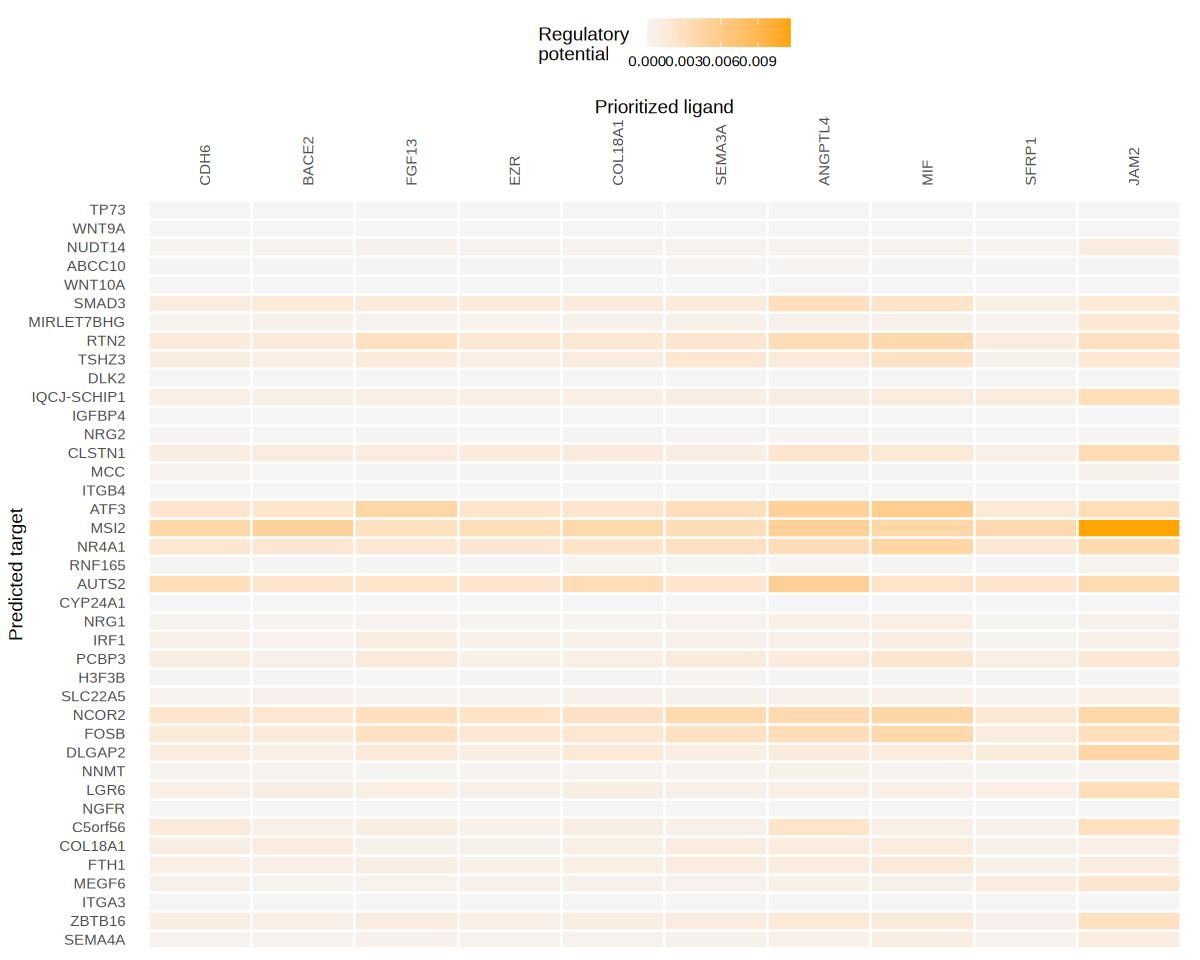

In [29]:
options(repr.plot.width = 10, repr.plot.height = 8)

native_receiver <- "basal"
native_ligands <- head(top_ligands(receiver_results[[native_receiver]]), 10)
native_targets <- head(top_targets(receiver_results[[native_receiver]], n = 50), 40)

native_heatmap_matrix <- context_ltm[
    intersect(native_targets, rownames(context_ltm)),
    intersect(native_ligands, colnames(context_ltm)),
    drop = FALSE
]

cat("Native nichenetr heatmap input:", nrow(native_heatmap_matrix), "targets x", ncol(native_heatmap_matrix), "ligands\n")

if (nrow(native_heatmap_matrix) > 0 && ncol(native_heatmap_matrix) > 0) {
    suppressWarnings(print(nichenetr::make_heatmap_ggplot(
        native_heatmap_matrix,
        y_name = "Predicted target",
        x_name = "Prioritized ligand",
        legend_title = "Regulatory\npotential",
        color = "orange",
        x_axis_position = "top"
    )))
}



A static circos plot summarizes ligand-receptor paths from a native NicheNet-style prioritization table. The code below reuses `subset_data_top3`, converts the ContextNet path score to the `prioritization_score` column expected by `nichenetr::make_circos_lr()`, and keeps the same cell-type color map used in the ccflowR Sankey plot.



Native nichenetr ligand-receptor circos rows: 10 


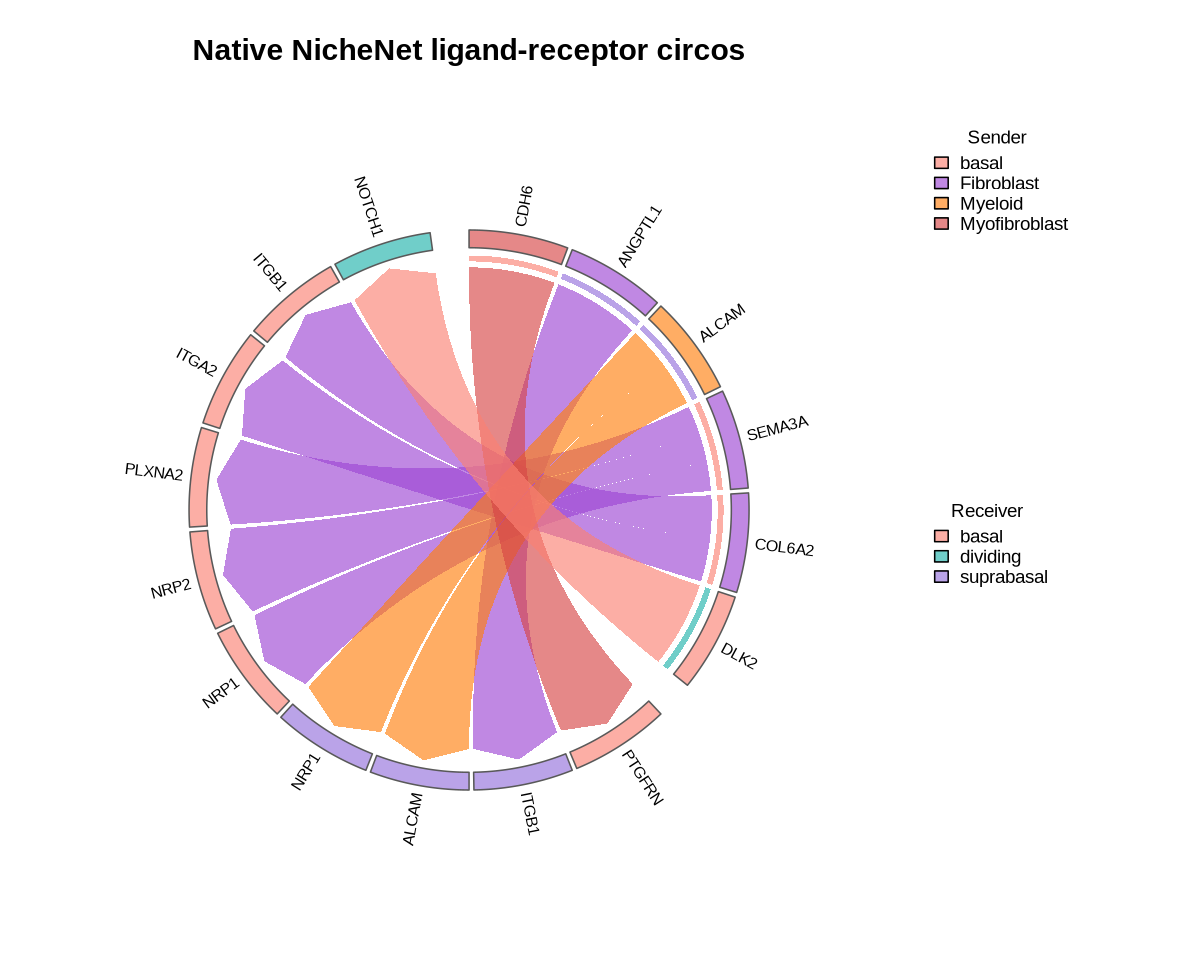

In [30]:
if (requireNamespace("circlize", quietly = TRUE)) {
    options(repr.plot.width = 10, repr.plot.height = 8)

    native_lr_tbl <- subset_data_top3 %>%
        arrange(desc(weighted_score)) %>%
        slice_head(n = 10) %>%
        mutate(prioritization_score = scaled_weighted_score) %>%
        select(sender, receiver, ligand, receptor, prioritization_score)

    native_senders <- sort(unique(native_lr_tbl$sender))
    native_receivers <- sort(unique(native_lr_tbl$receiver))
    native_sender_colors <- celltype_colors[native_senders]
    native_receiver_colors <- celltype_colors[native_receivers]
    if (any(is.na(native_sender_colors))) {
        native_sender_colors[is.na(native_sender_colors)] <- grDevices::hcl.colors(sum(is.na(native_sender_colors)), "Dark 3")
    }
    if (any(is.na(native_receiver_colors))) {
        native_receiver_colors[is.na(native_receiver_colors)] <- grDevices::hcl.colors(sum(is.na(native_receiver_colors)), "Dark 3")
    }



    save_static_circos_lr <- function(prioritized_tbl, sender_colors, receiver_colors, file,
                                      title = NULL, width = 1200, height = 960, res = 150) {
        dir.create(dirname(file), recursive = TRUE, showWarnings = FALSE)
        circos_tbl <- prioritized_tbl %>%
            ungroup() %>%
            mutate(
                circos_weight = pmax(as.numeric(prioritization_score), .Machine$double.eps),
                ligand_node = paste("L", sender, ligand, sep = "|"),
                receptor_node = paste("R", receiver, receptor, sep = "|")
            )
        ligand_nodes <- circos_tbl %>% distinct(ligand_node, sender, ligand)
        receptor_nodes <- circos_tbl %>% distinct(receptor_node, receiver, receptor)
        links_circle <- circos_tbl %>%
            group_by(ligand_node, receptor_node) %>%
            summarise(circos_weight = max(circos_weight, na.rm = TRUE), .groups = "drop")
        grid_col <- c(
            stats::setNames(sender_colors[ligand_nodes$sender], ligand_nodes$ligand_node),
            stats::setNames(receiver_colors[receptor_nodes$receiver], receptor_nodes$receptor_node)
        )
        grid_col[is.na(grid_col)] <- "#BDBDBD"
        sector_order <- c(ligand_nodes$ligand_node, receptor_nodes$receptor_node)
        gaps <- rep(1, length(sector_order))
        if (length(sector_order) > 1) {
            gaps[length(ligand_nodes$ligand_node)] <- 8
            gaps[length(sector_order)] <- 8
        }

        grDevices::png(file, width = width, height = height, res = res, bg = "white")
        on.exit({
            circlize::circos.clear()
            grDevices::dev.off()
        }, add = TRUE)
        graphics::layout(matrix(c(1, 2), nrow = 1), widths = c(4.2, 1.35))
        graphics::par(mar = c(1, 1, 3, 0))
        circlize::circos.clear()
        circlize::circos.par(gap.degree = gaps, start.degree = 90)
        circlize::chordDiagram(
            links_circle,
            directional = 1,
            order = sector_order,
            grid.col = grid_col,
            transparency = 0.35,
            annotationTrack = "grid",
            preAllocateTracks = list(track.height = 0.25),
            direction.type = c("diffHeight", "arrows"),
            link.arr.length = 0.04,
            link.arr.type = "big.arrow",
            grid.border = "gray35",
            link.lwd = 0.8,
            link.lty = 1,
            reduce = 0,
            scale = TRUE
        )
        circlize::circos.trackPlotRegion(
            track.index = 1,
            panel.fun = function(x, y) {
                sector <- circlize::get.cell.meta.data("sector.index")
                parts <- strsplit(sector, "\\|")[[1]]
                label <- parts[length(parts)]
                circlize::circos.text(
                    circlize::get.cell.meta.data("xcenter"),
                    circlize::get.cell.meta.data("ylim")[1],
                    label,
                    facing = "clockwise",
                    niceFacing = TRUE,
                    adj = c(0, 0.5),
                    cex = 0.62
                )
            },
            bg.border = NA
        )
        if (!is.null(title)) {
            graphics::title(title, line = 1)
        }
        graphics::par(mar = c(1, 0, 3, 1), xpd = NA)
        graphics::plot.new()
        graphics::plot.window(xlim = c(0, 1), ylim = c(0, 1))
        legend_cex <- if (length(sender_colors) > 8) 0.6 else 0.75
        graphics::legend(
            x = 0, y = 1, legend = names(sender_colors), fill = unname(sender_colors),
            title = "Sender", bty = "n", cex = legend_cex, x.intersp = 0.7, y.intersp = 0.9
        )
        receiver_y <- max(0.05, 1 - 0.08 * (length(sender_colors) + 2))
        graphics::legend(
            x = 0, y = receiver_y, legend = names(receiver_colors), fill = unname(receiver_colors),
            title = "Receiver", bty = "n", cex = 0.75, x.intersp = 0.7, y.intersp = 0.9
        )
        invisible(file)
    }

    display_static_png <- function(file) {
        if (requireNamespace("IRdisplay", quietly = TRUE)) {
            IRdisplay::display_png(file = file)
        } else {
            message("Static figure written to ", file)
        }
        invisible(file)
    }

    cat("Native nichenetr ligand-receptor circos rows:", nrow(native_lr_tbl), "\n")

    native_circos_file <- file.path(PROJECT_DIR, "notebooks", "figures", "02-native-circos.png")
    save_static_circos_lr(
        native_lr_tbl,
        native_sender_colors,
        native_receiver_colors,
        native_circos_file,
        title = "Native NicheNet ligand-receptor circos"
    )
    display_static_png(native_circos_file)
} else {
    message("Install circlize to draw native nichenetr circos plots.")
}



Static GitHub preview:

![Native NicheNet circos plot with sender and receiver legends](figures/02-native-circos.png)
